# ETTh1 SA-GHONN Prediction Example

Train a small Self-Attention Gated Higher-Order Neural Network (SA-GHONN) to forecast oil temperature (`OT`). We use the first 2,048 hourly ETTh1 measurements, observe the previous 48 hours, and predict the next 24 hours.

This is a quick usage example with a small model and ten training epochs. It is intended to run on a CPU; CUDA is used automatically when available. Forecast quality is illustrative.


In [7]:
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

import ghonn_models_pytorch as gmp
from ghonn_models_pytorch.datasets.data_loaders import ETTh1Dataset

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    # Small batches benefit from keeping CPU thread overhead low.
    torch.set_num_threads(min(4, torch.get_num_threads()))
print(f"Using device: {device}")


Using device: cuda


## Load a small ETTh1 sample

Download the public CSV and keep the first 2,048 rows. All seven measurements are model inputs; `OT` is the forecast target. Internet access is needed to download the data.


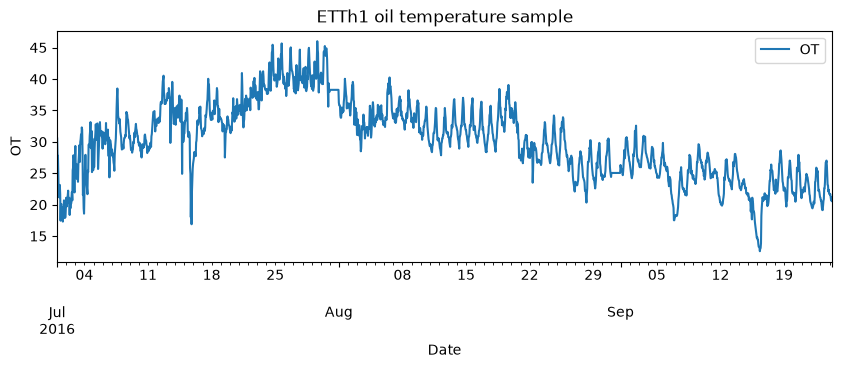

In [8]:
data = gmp.load_example_dataset("etth1", parse_dates=["date"]).iloc[:2048].copy()
data.plot(x="date", y="OT", figsize=(10, 3), title="ETTh1 oil temperature sample")
plt.xlabel("Date")
plt.ylabel("OT")
plt.show()


## Prepare training, validation, and test windows

Split the sample chronologically into 60% training, 20% validation, and 20% test data. `ETTh1Dataset` fits normalization on the training portion only. Validation and test inputs may include past observations from the preceding split, but their targets stay within their own split.


In [9]:
input_length = 48
prediction_length = 24
batch_size = 32

dataset_args = {
    "input_length": input_length,
    "prediction_length": prediction_length,
    "target": "OT",
    "train_ratio": 0.6,
    "validation_ratio": 0.2,
}
train_set = ETTh1Dataset(data, split="train", **dataset_args)
validation_set = ETTh1Dataset(data, split="validation", **dataset_args)
test_set = ETTh1Dataset(data, split="test", **dataset_args)

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(validation_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)

x, y = next(iter(train_loader))
print(f"Train/validation/test windows: {len(train_set)}/{len(validation_set)}/{len(test_set)}")
print(f"Input shape: {tuple(x.shape)}, target shape: {tuple(y.shape)}")


Train/validation/test windows: 1157/387/387
Input shape: (32, 48, 7), target shape: (32, 24, 1)


## Train a small SA-GHONN

Keep the three expert branches, using a model width of 16, two attention heads, four-hour temporal windows, and low polynomial orders. Train for ten epochs and restore the checkpoint with the lowest validation loss. The explicit settings below keep the example small independently of the library's defaults.


In [10]:
epochs = 10
torch.manual_seed(42)
model = gmp.SAGHONN(
    input_length=input_length,
    in_features=len(train_set.feature_names),
    out_features=prediction_length,
    predicted_feature_indices=(train_set.target_index,),
    d_model=16,
    n_heads=2,
    n_layers=1,
    ffn_dim=32,
    decoder_hidden_dim=32,
    temporal_lookback=3,
    predictor_orders=(1, 2),
    gate_orders=(1,),
    predictor_activations=("identity", "tanh"),
    gate_activations=("sigmoid",),
    conv_kernel_size=3,
    conv_n_kernels=2,
    trend_kernel_size=13,
    seasonal_kernel_size=3,
    dropout=0.05,
    head_dropout=0.0,
    poly_dropout=0.0,
).to(device)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
loss_fn = torch.nn.MSELoss()
train_losses, validation_losses = [], []
best_validation_loss = float("inf")
best_state = None

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(x)
    train_losses.append(total_loss / len(train_set))

    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for x, y in validation_loader:
            x, y = x.to(device), y.to(device)
            total_loss += loss_fn(model(x), y).item() * len(x)
    validation_losses.append(total_loss / len(validation_set))
    if validation_losses[-1] < best_validation_loss:
        best_validation_loss = validation_losses[-1]
        best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
    print(
        f"Epoch {epoch + 1}/{epochs}: "
        f"train MSE={train_losses[-1]:.4f}, validation MSE={validation_losses[-1]:.4f}"
    )

model.load_state_dict(best_state)
print(f"Restored best validation MSE: {best_validation_loss:.4f}")


Trainable parameters: 12,944
Epoch 1/10: train MSE=0.3968, validation MSE=0.3222
Epoch 2/10: train MSE=0.3173, validation MSE=0.2782
Epoch 3/10: train MSE=0.2720, validation MSE=0.2527
Epoch 4/10: train MSE=0.2392, validation MSE=0.2468
Epoch 5/10: train MSE=0.1989, validation MSE=0.2585
Epoch 6/10: train MSE=0.1762, validation MSE=0.2527
Epoch 7/10: train MSE=0.1558, validation MSE=0.2724
Epoch 8/10: train MSE=0.1468, validation MSE=0.2730
Epoch 9/10: train MSE=0.1335, validation MSE=0.2651
Epoch 10/10: train MSE=0.1285, validation MSE=0.2801
Restored best validation MSE: 0.2468


## Plot training and validation loss

Loss is measured on normalized values. The forecast uses the checkpoint with the lowest validation loss, which may occur before the final epoch.


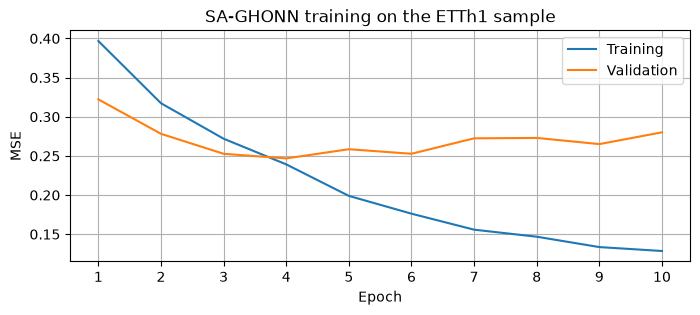

In [11]:
plt.figure(figsize=(8, 3))
plt.plot(range(1, epochs + 1), train_losses, label="Training")
plt.plot(range(1, epochs + 1), validation_losses, label="Validation")
plt.title("SA-GHONN training on the ETTh1 sample")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid()
plt.show()


## Forecast an unseen test window

Predict the next 24 hours for the first test window, then convert the forecast and actual values back to the original temperature scale.


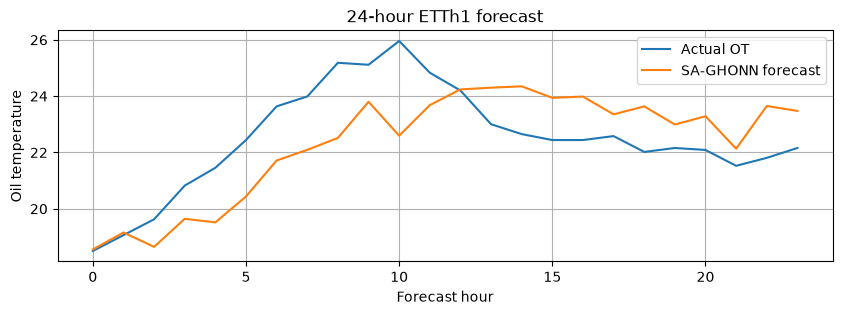

In [12]:
model.eval()
x, actual = next(iter(test_loader))
with torch.no_grad():
    predicted = model(x.to(device)).cpu().numpy()[0, :, 0]

actual = actual.numpy()[0, :, 0]
predicted = test_set.inverse_target(predicted)
actual = test_set.inverse_target(actual)

plt.figure(figsize=(10, 3))
plt.plot(actual, label="Actual OT")
plt.plot(predicted, label="SA-GHONN forecast")
plt.title(f"{prediction_length}-hour ETTh1 forecast")
plt.xlabel("Forecast hour")
plt.ylabel("Oil temperature")
plt.legend()
plt.grid()
plt.show()
